In [23]:
import os
from dotenv import load_dotenv

load_dotenv()

os.environ['GROQ_API_KEY']=os.getenv("GROQ_API_KEY")

from langchain_groq import ChatGroq
llm=ChatGroq(model='openai/gpt-oss-120b')

In [24]:
from langgraph.graph import StateGraph,START,END
from typing import Annotated
from langgraph.graph.message import add_messages
from typing_extensions import TypedDict
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode,tools_condition
from langgraph.types import interrupt, Command

In [25]:
class State(TypedDict):
    messages : Annotated[list,add_messages]

In [26]:
@tool
def human_assistance(query: str):
    """Request assisatnce from human"""

    human_response = interrupt(
        f"Human assistance requested:\n{query}\n\nPlease provide the human response."
    )

    return human_response


In [27]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)

In [28]:
tools=[tool,human_assistance]

llm_with_tool=llm.bind_tools(tools)

In [33]:
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.prebuilt import ToolNode, tools_condition


graph_builder = StateGraph(State)


def chatbot(state: State):

    res = llm_with_tool.invoke(state["messages"])

    return {
        "messages": [res]
    }


graph_builder.add_node(
    "llm_with_tool",
    chatbot
)


graph_builder.add_node(
    "tools",
    ToolNode(tools)
)


graph_builder.add_edge(
    START,
    "llm_with_tool"
)


graph_builder.add_conditional_edges(
    "llm_with_tool",
    tools_condition
)


graph_builder.add_edge(
    "tools",
    "llm_with_tool"
)


memory = MemorySaver()

graph = graph_builder.compile(
    checkpointer=memory
)

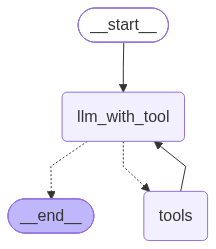

In [34]:

from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [35]:
user_input = "I need human like assistance, could you guide me?"

config1 = {
    "configurable": {
        "thread_id": "chat1"
    }
}

events = graph.stream(
    {"messages": user_input},
    config1,
    stream_mode="values"
)

for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================ Human Message =================================

I need human like assistance, could you guide me?
================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_dbc63e3b-96d1-491d-99b2-d29d7c0b7247)
 Call ID: fc_dbc63e3b-96d1-491d-99b2-d29d7c0b7247
  Args:
    query: User requests human-like assistance and guidance.
================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_dbc63e3b-96d1-491d-99b2-d29d7c0b7247)
 Call ID: fc_dbc63e3b-96d1-491d-99b2-d29d7c0b7247
  Args:
    query: User requests human-like assistance and guidance.


In [36]:
from langgraph.types import Command

result = graph.invoke(
    Command(resume="yes"),
    config=config1
)

for message in result["messages"]:
    message.pretty_print()

================================ Human Message =================================

I need human like assistance, could you guide me?
================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_dbc63e3b-96d1-491d-99b2-d29d7c0b7247)
 Call ID: fc_dbc63e3b-96d1-491d-99b2-d29d7c0b7247
  Args:
    query: User requests human-like assistance and guidance.
================================= Tool Message =================================
Name: human_assistance

yes
================================== Ai Message ==================================

Absolutely—I’m here to help! To make sure you get the most useful, “human‑like” assistance, it helps to be a little specific about what you need. Here’s a quick guide you can follow:

---

## 1️⃣ Clarify the Goal  
**What are you trying to accomplish?**  
- Are you looking for **information** (e.g., research, facts, how‑to steps)?  
- Do you need **advice** (e.g., career, relationships, health, financ